# NOTEBOOK 2 : U-Net From Scratch

---



## Cellule 0 :     Optimisation Mémoire Préventive

Nettoyer et préparer la mémoire **avant** de charger le modèle et les données pour éviter les crashs "Out of Memory" (OOM).

---

In [ ]:
import os
import gc
import sys

# ==============================================================================
# OPTIMISATION MÉMOIRE PRÉVENTIVE
# ==============================================================================

# 1. Configuration Anti-Fragmentation (CRUCIAL pour éviter le crash OOM)
# Doit être défini avant que PyTorch ne commence à allouer de la mémoire
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

print(" Démarrage du nettoyage mémoire...")

# 2. Nettoyage de la RAM Python (Variables inutilisées)
gc.collect()
print("   ✓ RAM Python nettoyée")

# 3. Nettoyage du Cache GPU (PyTorch)
if 'torch' in sys.modules:
    try:
        import torch
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
            torch.cuda.ipc_collect()
            print(f"   ✓ Cache GPU PyTorch vidé (Mémoire libre: {torch.cuda.mem_get_info()[0]/1024**3:.2f} GB)")
    except Exception as e:
        print(f"    Pas de nettoyage PyTorch nécessaire ou erreur: {e}")

# 4. Nettoyage Session Keras (Si utilisé précédemment)
if 'tensorflow' in sys.modules:
    try:
        import tensorflow as tf
        tf.keras.backend.clear_session()
        print("   ✓ Session TensorFlow/Keras fermée")
    except:
        pass

print("\n PRÊT À DÉMARRER. (Vos fichiers dans /kaggle/working/ sont intacts)")

 Démarrage du nettoyage mémoire...
   ✓ RAM Python nettoyée
   ✓ Session TensorFlow/Keras fermée

 PRÊT À DÉMARRER. (Vos fichiers dans /kaggle/working/ sont intacts)


## Cellule 1 :      Imports et Configuration


Importer toutes les bibliothèques nécessaires pour construire et entraîner le modèle U-Net.

---

### Bibliothèques importées :

| Catégorie | Bibliothèques | Usage |
|-----------|---------------|-------|
| **Standard** | `os`, `json`, `random`, `pathlib` | Gestion fichiers et chemins |
| **Data** | `numpy`, `pandas` | Manipulation des données |
| **Deep Learning** | `tensorflow`, `keras` | Construction et entraînement U-Net |
| **Visualisation** | `matplotlib`, `seaborn` | Graphiques et courbes |
| **Évaluation** | `sklearn.metrics` | Matrice de confusion, rapport |

---

### Composants Keras importés :

| Composant | Rôle dans U-Net |
|-----------|-----------------|
| `Conv2D` | Couches de convolution |
| `MaxPooling2D` | Réduction spatiale (encoder) |
| `Conv2DTranspose` | Upsampling (decoder) |
| `concatenate` | Skip connections |
| `BatchNormalization` | Stabilisation de l'entraînement |
| `LeakyReLU` | Fonction d'activation |
| `Dropout` | Régularisation |

---

### Callbacks importés :

| Callback | Fonction |
|----------|----------|
| `EarlyStopping` | Arrêt si pas d'amélioration |
| `ReduceLROnPlateau` | Réduire le learning rate |
| `ModelCheckpoint` | Sauvegarder le meilleur modèle |
| `TensorBoard` | Visualisation des logs |
| `CSVLogger` | Historique en CSV |

In [ ]:

# ========================================================================================================
# 1. IMPORTS ET CONFIGURATION
# ========================================================================================================
import os
import json
import random
import numpy as np
import pandas as pd
from pathlib import Path
from typing import Dict, List, Tuple
import warnings
warnings.filterwarnings('ignore')

# Deep Learning
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D, Conv2DTranspose,
    concatenate, BatchNormalization, LeakyReLU, Dropout
)
from tensorflow.keras.optimizers import Adam, RMSprop
from tensorflow.keras.callbacks import (
    EarlyStopping, ReduceLROnPlateau, ModelCheckpoint,
    TensorBoard, CSVLogger
)
import tensorflow.keras.backend as K

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
from datetime import datetime

# Sklearn
from sklearn.metrics import classification_report, confusion_matrix

# Set style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

print("="*80)
print("DEEPGLOBE LAND COVER SEGMENTATION - U-NET FROM SCRATCH")
print("="*80)
print(f"\nExecution Date: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
print(f"TensorFlow Version: {tf.__version__}")
print(f"GPU Available: {tf.config.list_physical_devices('GPU')}")

DEEPGLOBE LAND COVER SEGMENTATION - U-NET FROM SCRATCH

Execution Date: 2025-12-18 17:15:24
TensorFlow Version: 2.19.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## Cellule 2 :       Configuration Centralisée

Définir tous les paramètres du projet dans une seule classe pour faciliter la gestion et la reproductibilité.

---

### Paramètres de Configuration :

#### Reproductibilité
| Paramètre | Valeur | Description |
|-----------|--------|-------------|
| `SEED` | 42 | Graine aléatoire pour résultats reproductibles |

#### Chemins
| Paramètre | Chemin | Contenu |
|-----------|--------|---------|
| `DATA_DIR` | `/kaggle/working/preprocessed_data` | Données prétraitées (Notebook 1) |
| `OUTPUT_DIR` | `/kaggle/working/unet_from_scratch` | Résultats U-Net |
| `MODELS_DIR` | `.../models` | Modèles sauvegardés (. h5) |
| `LOGS_DIR` | `.../logs` | Historique d'entraînement |
| `FIGURES_DIR` | `.../figures` | Graphiques et visualisations |

#### Architecture U-Net
| Paramètre | Valeur | Description |
|-----------|--------|-------------|
| `INPUT_SHAPE` | (256, 256, 3) | Taille des images RGB |
| `NUM_CLASSES` | 6 | Nombre de classes de segmentation |

#### Hyperparamètres d'Entraînement
| Paramètre | Valeur | Description |
|-----------|--------|-------------|
| `BATCH_SIZE` | 16 | Images par batch |
| `EPOCHS` | 100 | Maximum d'itérations |
| `LEARNING_RATE` | 1e-4 (0.0001) | Vitesse d'apprentissage |
| `OPTIMIZER` | RMSprop | Algorithme d'optimisation |

#### Callbacks
| Paramètre | Valeur | Description |
|-----------|--------|-------------|
| `EARLY_STOPPING_PATIENCE` | 10 | Arrêt après 10 epochs sans amélioration |
| `REDUCE_LR_PATIENCE` | 5 | Réduire LR après 5 epochs sans amélioration |
| `REDUCE_LR_FACTOR` | 0.5 | Diviser LR par 2 |

#### Classes
| ID | Nom | Couleur |
|----|-----|---------|
| 0 | urban | Cyan |
| 1 | agriculture | Jaune |
| 2 | rangeland | Magenta |
| 3 | forest | Vert |
| 4 | water | Bleu |
| 5 | barren | Blanc |

In [ ]:
# ========================================================================================================
# 2. CONFIGURATION
# ========================================================================================================
class Config:
    """Configuration centralisée"""
    # Reproductibilité
    SEED = 42

    # Chemins
    DATA_DIR = Path('/kaggle/working/preprocessed_data')
    OUTPUT_DIR = Path('/kaggle/working/unet_from_scratch')
    MODELS_DIR = OUTPUT_DIR / 'models'
    LOGS_DIR = OUTPUT_DIR / 'logs'
    FIGURES_DIR = OUTPUT_DIR / 'figures'

    # Architecture U-Net
    INPUT_SHAPE = (256, 256, 3)
    NUM_CLASSES = 6  # urban, agriculture, rangeland, forest, water, barren

    # Hyperparamètres
    BATCH_SIZE = 16
    EPOCHS = 100
    LEARNING_RATE = 1e-4
    OPTIMIZER = 'rmsprop'  # 'adam' ou 'rmsprop'

    # Callbacks
    EARLY_STOPPING_PATIENCE = 10
    REDUCE_LR_PATIENCE = 5
    REDUCE_LR_FACTOR = 0.5

    # Classes
    CLASS_NAMES = ['urban', 'agriculture', 'rangeland', 'forest', 'water', 'barren']
    CLASS_COLORS = {
        0: (0, 255, 255),      # urban - cyan
        1: (255, 255, 0),      # agriculture - yellow
        2: (255, 0, 255),      # rangeland - magenta
        3: (0, 255, 0),        # forest - green
        4: (0, 0, 255),        # water - blue
        5: (255, 255, 255)     # barren - white
    }

config = Config()

# Création des dossiers
for directory in [config.OUTPUT_DIR, config.MODELS_DIR, config.LOGS_DIR, config.FIGURES_DIR]:
    directory.mkdir(parents=True, exist_ok=True)
    print(f"✓ Created directory: {directory}")

✓ Created directory: /kaggle/working/unet_from_scratch
✓ Created directory: /kaggle/working/unet_from_scratch/models
✓ Created directory: /kaggle/working/unet_from_scratch/logs
✓ Created directory: /kaggle/working/unet_from_scratch/figures


## Cellule 3 :       Reproductibilité


Fixer toutes les graines aléatoires pour garantir que les résultats soient **identiques** à chaque exécution.

In [ ]:
# ========================================================================================================
# 3. REPRODUCTIBILITÉ
# ========================================================================================================
def set_seed(seed: int = 42):
    """Fixe tous les seeds pour reproductibilité"""
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    os.environ['TF_DETERMINISTIC_OPS'] = '1'
    print(f"\n✓ All seeds set to {seed} for reproducibility")

set_seed(config.SEED)


✓ All seeds set to 42 for reproducibility


## Cellule 4 :        Chargement des Données Prétraitées

Charger les fichiers `.npy` créés dans le Notebook 1 et préparer les données pour l'entraînement.

---

### Données chargées :

| Variable | Shape | Type | Description |
|----------|-------|------|-------------|
| `X_train` | (642, 256, 256, 3) | float32 | 642 images RGB normalisées [0-1] |
| `y_train` | (642, 256, 256) | uint8 | 642 masques avec classes [0-5] |
| `X_val` | (161, 256, 256, 3) | float32 | 161 images validation |
| `y_val` | (161, 256, 256) | uint8 | 161 masques validation |
| `X_test` | (172, 256, 256, 3) | float32 | 172 images test (sans masques) |

---

### One-Hot Encoding :       Pourquoi ?   

La fonction softmax de sortie attend un format **one-hot** (une colonne par classe).

```
Avant (indices):                 Après (one-hot):
┌─────┐                          ┌───┬───┬───┬───┬───┬───┐
│  1  │  (agriculture)     →     │ 0 │ 1 │ 0 │ 0 │ 0 │ 0 │
├─────┤                          ├───┼───┼───┼───┼───┼───┤
│  3  │  (forest)          →     │ 0 │ 0 │ 0 │ 1 │ 0 │ 0 │
├─────┤                          ├───┼───┼───┼───┼───┼───┤
│  4  │  (water)           →     │ 0 │ 0 │ 0 │ 0 │ 1 │ 0 │
└─────┘                          └───┴───┴───┴───┴───┴───┘

Shape: (642, 256, 256)     →     Shape: (642, 256, 256, 6)
```

---

### Class Weights chargés :

| Classe | Poids | Interprétation |
|--------|-------|----------------|
| water | **1.0000** | Pénalité maximale si erreur |
| rangeland | 0.3904 | Pénalité élevée |
| barren | 0.3920 | Pénalité élevée |
| urban | 0.3066 | Pénalité moyenne |
| forest | 0.2968 | Pénalité moyenne |
| agriculture | **0.0574** | Pénalité faible (classe dominante) |

**Utilisation** : Ces poids seront intégrés dans la **Weighted Dice Loss** pour équilibrer l'apprentissage.

In [ ]:
# ========================================================================================================
# 4. CHARGEMENT DES DONNÉES
# ========================================================================================================
print("\n" + "="*80)
print("4. CHARGEMENT DES DONNÉES PRÉTRAITÉES")
print("="*80)

# Charger les données
X_train = np.load(config.DATA_DIR / 'train_images.npy')
y_train = np.load(config.DATA_DIR / 'train_masks.npy')
X_val = np.load(config.DATA_DIR / 'val_images.npy')
y_val = np.load(config.DATA_DIR / 'val_masks.npy')
X_test = np.load(config.DATA_DIR / 'test_images.npy')

# Charger métadonnées et class weights
with open(config.DATA_DIR / 'metadata.json', 'r') as f:
    metadata = json.load(f)

with open(config.DATA_DIR / 'class_weights.json', 'r') as f:
    class_weights_data = json.load(f)
    class_weights_dict = {int(k): v for k, v in class_weights_data['inverse_frequency'].items()}

print(f"\n Données chargées:")
print(f" • X_train: {X_train.shape} | dtype: {X_train.dtype} | range: [{X_train.min():.3f}, {X_train.max():.3f}]")
print(f" • y_train: {y_train.shape} | dtype: {y_train.dtype} | unique classes: {np.unique(y_train)}")
print(f" • X_val: {X_val.shape}")
print(f" • y_val: {y_val.shape}")
print(f" • X_test: {X_test.shape}")

# Convertir les masques en one-hot encoding
print("\n Conversion des masques en one-hot encoding...")
y_train_onehot = tf.keras.utils.to_categorical(y_train, num_classes=config.NUM_CLASSES)
y_val_onehot = tf.keras.utils.to_categorical(y_val, num_classes=config.NUM_CLASSES)

print(f" • y_train_onehot: {y_train_onehot.shape}")
print(f" • y_val_onehot: {y_val_onehot.shape}")

print("\n Class weights:")
for class_id, weight in class_weights_dict.items():
    print(f" • {config.CLASS_NAMES[class_id]:15s}: {weight:.4f}")


4. CHARGEMENT DES DONNÉES PRÉTRAITÉES

 Données chargées:
 • X_train: (642, 256, 256, 3) | dtype: float32 | range: [0.000, 1.000]
 • y_train: (642, 256, 256) | dtype: uint8 | unique classes: [0 1 2 3 4 5]
 • X_val: (161, 256, 256, 3)
 • y_val: (161, 256, 256)
 • X_test: (172, 256, 256, 3)

 Conversion des masques en one-hot encoding...
 • y_train_onehot: (642, 256, 256, 6)
 • y_val_onehot: (161, 256, 256, 6)

 Class weights:
 • urban          : 0.3066
 • agriculture    : 0.0574
 • rangeland      : 0.3904
 • forest         : 0.2968
 • water          : 1.0000
 • barren         : 0.3920



| Ensemble | Normalisation | Fichier |
|----------|---------------|---------|
| Train | **÷ 255 → [0-1]** | train_images.npy |
| Validation | **÷ 255 → [0-1]** | val_images.npy |
| Test | **÷ 255 → [0-1]** | test_images. npy |

## Cellule 5 :          Métriques Personnalisées

Définir des métriques spécifiques à la **segmentation sémantique** pour évaluer et entraîner le modèle.

---

### 1. Dice Coefficient (F1-Score pour segmentation)

**Formule** :
```
Dice = (2 × Intersection) / (Prédiction + Vérité)
```

**Illustration** :
```
Vérité (GT):     Prédiction:        Intersection:
┌───────────┐    ┌───────────┐    ┌───────────┐
│███████    │    │  ███████  │    │  █████    │
│███████    │    │  ███████  │    │  █████    │
│███████    │    │  ███████  │    │  █████    │
└───────────┘    └───────────┘    └───────────┘
   A=21             B=21            A∩B=15

Dice = (2 × 15) / (21 + 21) = 30/42 = 0.71
```

| Dice | Interprétation |
|------|----------------|
| 1.0 | Parfait (100% overlap) |
| 0.8+ | Excellent |
| 0.6-0.8 | Bon |
| < 0.5 | Faible |

---

### 2. IoU (Intersection over Union / Jaccard)

**Formule** :
```
IoU = Intersection / Union
```

**Illustration** :
```
        Intersection          Union (A ∪ B)
        ┌─────┐               ┌───────────┐
        │█████│               │███████████│
        │█████│               │███████████│
        └─────┘               │███████████│
          15                  └───────────┘
                                   27

IoU = 15 / 27 = 0.56
```

**Relation Dice-IoU** :  `Dice = 2×IoU / (1+IoU)`

---

### 3. Dice Loss

```python
Dice Loss = 1 - Dice Coefficient
```

| Dice Coefficient | Dice Loss | Signification |
|------------------|-----------|---------------|
| 0.9 | 0.1 | Bonne prédiction → faible pénalité |
| 0.5 | 0.5 | Moyenne → pénalité moyenne |
| 0.1 | 0.9 | Mauvaise → forte pénalité |

---

### 4. Weighted Dice Loss (Pondérée)

**Problème** : Classes déséquilibrées (agriculture 57% vs water 3%)

**Solution** : Multiplier la loss de chaque classe par son poids

```python
weighted_dice = (1 - dice) × class_weight

# Exemple :
water_loss    = (1 - 0.7) × 1.00 = 0.30  # Poids fort → pénalité élevée
agri_loss     = (1 - 0.7) × 0.06 = 0.018 # Poids faible → pénalité faible
```

**Effet** : Le modèle est **forcé** d'apprendre les classes rares (water, rangeland).

---

### Résumé des métriques :

| Métrique | Usage | Objectif |
|----------|-------|----------|
| `dice_coefficient` | Évaluation | Maximiser (→ 1) |
| `iou_metric` | Évaluation | Maximiser (→ 1) |
| `dice_loss` | Entraînement | Minimiser (→ 0) |
| `weighted_dice_loss` | Entraînement | Minimiser + équilibrer classes |

In [ ]:
# ========================================================================================================
# 5. MÉTRIQUES PERSONNALISÉES
# ========================================================================================================
print("\n" + "="*80)
print("5. DÉFINITION DES MÉTRIQUES PERSONNALISÉES")
print("="*80)

def dice_coefficient(y_true, y_pred, smooth=1):
    """
    Coefficient de Dice (F1-Score pour la segmentation)
    Mesure la similarité entre la prédiction et la vérité terrain
    """
    y_true = K.cast(y_true, 'float32')
    y_pred = K.cast(y_pred, 'float32')
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(y_true_f * y_pred_f)
    return (2. * intersection + smooth) / (K.sum(y_true_f) + K.sum(y_pred_f) + smooth)

def dice_loss(y_true, y_pred):
    """Loss basée sur le coefficient de Dice (1 - Dice)"""
    return 1 - dice_coefficient(y_true, y_pred)

def iou_metric(y_true, y_pred, smooth=1):
    """
    Intersection over Union (IoU) / Jaccard Index
    Mesure le chevauchement entre prédiction et vérité terrain
    """
    y_true = K.cast(y_true, 'float32')
    y_pred = K.cast(y_pred, 'float32')
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(y_true_f * y_pred_f)
    union = K.sum(y_true_f) + K.sum(y_pred_f) - intersection
    return (intersection + smooth) / (union + smooth)

def weighted_dice_loss(class_weights, smooth=1e-6):
    """
    Dice Loss pondérée par classe pour gérer le déséquilibre
    """
    def loss(y_true, y_pred):
        y_true = K.cast(y_true, 'float32')
        y_pred = K.cast(y_pred, 'float32')
        num_classes = y_pred.shape[-1]

        dice_per_class = []
        for i in range(num_classes):
            y_true_f = K.flatten(y_true[..., i])
            y_pred_f = K.flatten(y_pred[..., i])
            intersection = K.sum(y_true_f * y_pred_f)
            dice = (2. * intersection + smooth) / (K.sum(y_true_f) + K.sum(y_pred_f) + smooth)
            weighted_dice = (1 - dice) * class_weights.get(i, 1.0)
            dice_per_class.append(weighted_dice)

        return K.mean(K.stack(dice_per_class))
    return loss

print("✓ Métriques définies:")
print(" • dice_coefficient: Mesure de similarité")
print(" • dice_loss: Loss pour l'optimisation")
print(" • iou_metric: Intersection over Union")
print(" • weighted_dice_loss: Loss pondérée pour déséquilibre de classes")


5. DÉFINITION DES MÉTRIQUES PERSONNALISÉES
✓ Métriques définies:
 • dice_coefficient: Mesure de similarité
 • dice_loss: Loss pour l'optimisation
 • iou_metric: Intersection over Union
 • weighted_dice_loss: Loss pondérée pour déséquilibre de classes


## Cellule 6 :            Architecture U-Net From Scratch

Construire l'architecture complète du réseau **U-Net** pour la segmentation sémantique.

---

### Structure U-Net :  

```
                        ENCODER                              DECODER
                    (Contraction)                          (Expansion)
                         
Input 256×256×3                                          Output 256×256×6
       │                                                        ▲
       ▼                                                        │
┌──────────────┐                                      ┌──────────────┐
│  Conv 64     │ ─────────── Skip Connection ─────────│  Conv 64     │
│  256×256     │                                      │  256×256     │
└──────┬───────┘                                      └──────▲───────┘
       │ MaxPool                                    UpConv   │
       ▼                                                     │
┌──────────────┐                                      ┌──────────────┐
│  Conv 128    │ ─────────── Skip Connection ─────────│  Conv 128    │
│  128×128     │                                      │  128×128     │
└──────┬───────┘                                      └──────▲───────┘
       │ MaxPool                                    UpConv   │
       ▼                                                     │
┌──────────────┐                                      ┌──────────────┐
│  Conv 256    │ ─────────── Skip Connection ─────────│  Conv 256    │
│  64×64       │                                      │  64×64       │
└──────┬───────┘                                      └──────▲───────┘
       │ MaxPool                                    UpConv   │
       ▼                                                     │
┌──────────────┐                                      ┌──────────────┐
│  Conv 512    │ ─────────── Skip Connection ─────────│  Conv 512    │
│  32×32       │                                      │  32×32       │
└──────┬───────┘                                      └──────▲───────┘
       │ MaxPool                                    UpConv   │
       ▼                                                     │
       └─────────────┐ BRIDGE (Bottleneck) ┌─────────────────┘
                     │     Conv 1024       │
                     │      16×16          │
                     │   + Dropout 0.3     │
                     └─────────────────────┘
```

---

### Bloc de Convolution (`conv_block`) :

```
Input
  │
  ▼
Conv2D (3×3, same padding)
  │
  ▼
LeakyReLU (α=0.1)
  │
  ▼
BatchNormalization
  │
  ▼
Conv2D (3×3, same padding)
  │
  ▼
LeakyReLU (α=0.1)
  │
  ▼
BatchNormalization
  │
  ▼
Dropout (optionnel)
  │
  ▼
Output
```

---

### Composants expliqués :

| Composant | Fonction | Paramètres |
|-----------|----------|------------|
| **Conv2D** | Extraction de features | kernel 3×3, padding='same' |
| **LeakyReLU** | Activation non-linéaire | α=0.1 (évite "dying ReLU") |
| **BatchNorm** | Stabilise l'entraînement | Normalise les activations |
| **MaxPooling2D** | Réduit la résolution | 2×2, stride=2 |
| **Conv2DTranspose** | Augmente la résolution | 2×2, stride=2 |
| **Concatenate** | Skip connections | Fusionne encoder + decoder |
| **Dropout** | Régularisation | 30% au bridge seulement |

---

### Évolution des dimensions :

| Niveau | Encoder | Bridge | Decoder |
|--------|---------|--------|---------|
| 1 | 256×256×64 | — | 256×256×64 |
| 2 | 128×128×128 | — | 128×128×128 |
| 3 | 64×64×256 | — | 64×64×256 |
| 4 | 32×32×512 | — | 32×32×512 |
| 5 | — | **16×16×1024** | — |

---

### Skip Connections :      Pourquoi ?

| Sans Skip | Avec Skip |
|-----------|-----------|
| Perte d'information spatiale | Conservation des détails fins |
| Contours flous | Contours précis |
| Features abstraites seulement | Features locales + globales |

```python
# Concatenation dans le decoder
up4 = Conv2DTranspose(512, ... )(bridge)     # 32×32×512 (upsampled)
up4 = concatenate([up4, conv4])              # 32×32×1024 (+ encoder features)
```

---

### Couche de Sortie :

```python
outputs = Conv2D(num_classes, (1, 1), activation='softmax')(conv8)
# Shape: (256, 256, 6)
```

| Aspect | Valeur | Raison |
|--------|--------|--------|
| Kernel | 1×1 | Classification pixel par pixel |
| Filtres | 6 | Une probabilité par classe |
| Activation | Softmax | Probabilités sommant à 1 |

---

### Paramètres du Modèle :

```
Total:           31,055,622 paramètres
Trainable:     31,043,846
Non-trainable:      11,776 (BatchNorm:  mean, variance)
```

In [ ]:
# ========================================================================================================
# 6. ARCHITECTURE U-NET
# ========================================================================================================
print("\n" + "="*80)
print("6. CONSTRUCTION DE L'ARCHITECTURE U-NET FROM SCRATCH")
print("="*80)

def conv_block(inputs, filters, kernel_size=3, activation='leaky_relu',
               batch_norm=True, dropout=0.0):
    """
    Bloc de convolution standard pour U-Net
    Conv2D -> Activation -> BatchNorm -> Conv2D -> Activation -> BatchNorm -> Dropout
    """
    x = Conv2D(filters, kernel_size, padding='same')(inputs)

    if activation == 'leaky_relu':
        x = LeakyReLU(alpha=0.1)(x)
    else:
        x = tf.keras.layers.Activation(activation)(x)

    if batch_norm:
        x = BatchNormalization()(x)

    x = Conv2D(filters, kernel_size, padding='same')(x)

    if activation == 'leaky_relu':
        x = LeakyReLU(alpha=0.1)(x)
    else:
        x = tf.keras.layers.Activation(activation)(x)

    if batch_norm:
        x = BatchNormalization()(x)

    if dropout > 0:
        x = Dropout(dropout)(x)

    return x

def build_unet(input_shape=(256, 256, 3), num_classes=6):
    """
    Architecture U-Net complète

    Encoder (Contraction Path):
    - 5 niveaux de résolution descendante
    - Chaque niveau: 2x Conv2D + BatchNorm + LeakyReLU
    - MaxPooling2D pour réduire la résolution spatiale

    Bridge (Bottleneck):
    - Niveau le plus profond du réseau

    Decoder (Expansion Path):
    - 4 niveaux de résolution montante
    - Conv2DTranspose pour upsampling
    - Concatenation avec les features de l'encoder (skip connections)
    - Chaque niveau: 2x Conv2D + BatchNorm + LeakyReLU

    Output:
    - Conv2D 1x1 avec activation softmax pour classification pixel-wise
    """
    inputs = Input(shape=input_shape, name='input_image')

    # ==================== ENCODER (Contraction Path) ====================
    print("\n Building Encoder...")

    # Level 1: 256x256
    conv1 = conv_block(inputs, 64)
    pool1 = MaxPooling2D(pool_size=(2, 2))(conv1)
    print(f" • Level 1: {conv1.shape} -> MaxPool -> {pool1.shape}")

    # Level 2: 128x128
    conv2 = conv_block(pool1, 128)
    pool2 = MaxPooling2D(pool_size=(2, 2))(conv2)
    print(f" • Level 2: {conv2.shape} -> MaxPool -> {pool2.shape}")

    # Level 3: 64x64
    conv3 = conv_block(pool2, 256)
    pool3 = MaxPooling2D(pool_size=(2, 2))(conv3)
    print(f" • Level 3: {conv3.shape} -> MaxPool -> {pool3.shape}")

    # Level 4: 32x32
    conv4 = conv_block(pool3, 512)
    pool4 = MaxPooling2D(pool_size=(2, 2))(conv4)
    print(f" • Level 4: {conv4.shape} -> MaxPool -> {pool4.shape}")

    # ==================== BRIDGE (Bottleneck) ====================
    print("\n Building Bridge...")

    # Level 5 (Bridge): 16x16
    bridge = conv_block(pool4, 1024, dropout=0.3)
    print(f" • Bridge: {bridge.shape} (with dropout)")

    # ==================== DECODER (Expansion Path) ====================
    print("\n Building Decoder...")

    # Level 4: 32x32
    up4 = Conv2DTranspose(512, (2, 2), strides=(2, 2), padding='same')(bridge)
    up4 = concatenate([up4, conv4])
    conv5 = conv_block(up4, 512)
    print(f" • Level 4: {up4.shape} (concat) -> {conv5.shape}")

    # Level 3: 64x64
    up3 = Conv2DTranspose(256, (2, 2), strides=(2, 2), padding='same')(conv5)
    up3 = concatenate([up3, conv3])
    conv6 = conv_block(up3, 256)
    print(f" • Level 3: {up3.shape} (concat) -> {conv6.shape}")

    # Level 2: 128x128
    up2 = Conv2DTranspose(128, (2, 2), strides=(2, 2), padding='same')(conv6)
    up2 = concatenate([up2, conv2])
    conv7 = conv_block(up2, 128)
    print(f" • Level 2: {up2.shape} (concat) -> {conv7.shape}")

    # Level 1: 256x256
    up1 = Conv2DTranspose(64, (2, 2), strides=(2, 2), padding='same')(conv7)
    up1 = concatenate([up1, conv1])
    conv8 = conv_block(up1, 64)
    print(f" • Level 1: {up1.shape} (concat) -> {conv8.shape}")

    # ==================== OUTPUT ====================
    print("\n Building Output Layer...")

    outputs = Conv2D(num_classes, (1, 1), activation='softmax', name='output_segmentation')(conv8)
    print(f" • Output: {outputs.shape} (softmax activation)")

    # Créer le modèle
    model = Model(inputs=inputs, outputs=outputs, name='UNet_FromScratch')

    print("\n✓ U-Net architecture built successfully!")
    return model

# Construire le modèle
model = build_unet(input_shape=config.INPUT_SHAPE, num_classes=config.NUM_CLASSES)

# Afficher le résumé
print("\n" + "="*80)
print("MODEL SUMMARY")
print("="*80)
model.summary()

# Calculer le nombre de paramètres
total_params = model.count_params()
trainable_params = sum([K.count_params(w) for w in model.trainable_weights])
non_trainable_params = sum([K.count_params(w) for w in model.non_trainable_weights])

print(f"\n Paramètres du modèle:")
print(f" • Total: {total_params:,}")
print(f" • Trainable: {trainable_params:,}")
print(f" • Non-trainable: {non_trainable_params:,}")


6. CONSTRUCTION DE L'ARCHITECTURE U-NET FROM SCRATCH

 Building Encoder...
 • Level 1: (None, 256, 256, 64) -> MaxPool -> (None, 128, 128, 64)
 • Level 2: (None, 128, 128, 128) -> MaxPool -> (None, 64, 64, 128)
 • Level 3: (None, 64, 64, 256) -> MaxPool -> (None, 32, 32, 256)
 • Level 4: (None, 32, 32, 512) -> MaxPool -> (None, 16, 16, 512)

 Building Bridge...
 • Bridge: (None, 16, 16, 1024) (with dropout)

 Building Decoder...
 • Level 4: (None, 32, 32, 1024) (concat) -> (None, 32, 32, 512)
 • Level 3: (None, 64, 64, 512) (concat) -> (None, 64, 64, 256)
 • Level 2: (None, 128, 128, 256) (concat) -> (None, 128, 128, 128)
 • Level 1: (None, 256, 256, 128) (concat) -> (None, 256, 256, 64)

 Building Output Layer...
 • Output: (None, 256, 256, 6) (softmax activation)

✓ U-Net architecture built successfully!

MODEL SUMMARY


Model: "UNet_FromScratch"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_image         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 256, 256,  │      1,792 │ input_image[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu         │ (None, 256, 256,  │          0 │ conv2d[0][0]      │
│ (LeakyReLU)         │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 256, 256,  │        256 │ leaky_re_lu[0][0] │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 256, 256,  │     36,928 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_1       │ (None, 256, 256,  │          0 │ conv2d_1[0][0]    │
│ (LeakyReLU)         │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 256,  │        256 │ leaky_re_lu_1[0]… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 128, 128,  │     73,856 │ max_pooling2d[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_2       │ (None, 128, 128,  │          0 │ conv2d_2[0][0]    │
│ (LeakyReLU)         │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        512 │ leaky_re_lu_2[0]… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 128, 128,  │    147,584 │ batch_normalizat… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_3       │ (None, 128, 128,  │          0 │ conv2d_3[0][0]    │
│ (LeakyReLU)         │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        512 │ leaky_re_lu_3[0]… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 64, 64,    │    295,168 │ max_pooling2d_1[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_4       │ (None, 64, 64,    │          0 │ conv2d_4[0][0]  

 Total params: 31,055,622 (118.47 MB)

 Trainable params: 31,043,846 (118.42 MB)

 Non-trainable params: 11,776 (46.00 KB)


 Paramètres du modèle:
 • Total: 31,055,622
 • Trainable: 31,043,846
 • Non-trainable: 11,776


## Résumé de l'Architecture U-Net

> L'architecture U-Net implémentée est un réseau de neurones convolutif encodeur-décodeur composé de **31 millions de paramètres**. L'**encodeur** (chemin de contraction) comprend 4 niveaux qui réduisent progressivement la résolution spatiale de 256×256 à 16×16 pixels tout en augmentant le nombre de filtres de 64 à 1024, permettant l'extraction de caractéristiques de plus en plus abstraites.  Chaque niveau est constitué de deux convolutions 3×3 suivies d'activations LeakyReLU (α=0.1) et de normalisation par batch (BatchNormalization). Le **bridge** (goulot d'étranglement) à 16×16×1024 capture les représentations les plus profondes avec un dropout de 30% pour la régularisation. Le **décodeur** (chemin d'expansion) reconstruit la résolution spatiale via des convolutions transposées (upsampling), tandis que les **skip connections** concatènent les features de l'encodeur correspondant, préservant ainsi les informations spatiales fines essentielles à la précision des contours.  La couche de sortie utilise une convolution 1×1 avec activation **softmax** produisant une carte de segmentation 256×256×6 où chaque pixel reçoit une probabilité d'appartenance aux 6 classes de couverture terrestre.

---

## Cellule 7 :               Compilation du Modèle

Configurer le modèle pour l'entraînement en définissant l'optimiseur, la fonction de perte et les métriques d'évaluation.

---

### Configuration de la Compilation :

| Composant | Choix | Valeur |
|-----------|-------|--------|
| **Optimizer** | RMSprop | Learning rate = 1e-4 |
| **Loss** | Weighted Dice Loss | Pondérée par classe |
| **Metrics** | Dice + IoU | Évaluation de la segmentation |

---

### Pourquoi RMSprop :  

| Optimiseur | Caractéristiques | Quand l'utiliser |
|------------|------------------|------------------|
| **SGD** | Simple, stable | Grands datasets |
| **Adam** | Adaptatif, rapide | Usage général |
| **RMSprop** | Adaptatif, stable | Séquences, images, RNN |

**RMSprop** adapte le learning rate pour chaque paramètre, ce qui est efficace pour la segmentation d'images.

---

### Pourquoi Weighted Dice Loss :  

```python
loss = weighted_dice_loss(class_weights_dict)
```

| Sans pondération | Avec pondération |
|------------------|------------------|
| Agriculture (57%) domine | Toutes classes équilibrées |
| Water (3%) ignorée | Water bien apprise |
| Modèle biaisé | Modèle équitable |

**Poids appliqués** :
```
water:        1.00  ← Pénalité max (classe rare)
rangeland:   0.39
barren:      0.39
urban:       0.31
forest:      0.30
agriculture: 0.06  ← Pénalité min (classe dominante)
```

---

### Métriques d'Évaluation :  

| Métrique | Formule | Objectif |
|----------|---------|----------|
| **Dice Coefficient** | 2×Intersection / (Pred + GT) | Maximiser → 1 |
| **IoU** | Intersection / Union | Maximiser → 1 |

Ces métriques sont calculées à chaque epoch pour suivre la progression du modèle.

---

### Résumé :  

```
model.compile(
    optimizer = RMSprop(lr=0.0001),      # Vitesse d'apprentissage
    loss = weighted_dice_loss,            # Ce qu'on minimise
    metrics = [dice, iou]                 # Ce qu'on surveille
)

In [ ]:
# ========================================================================================================
# 7. COMPILATION DU MODÈLE
# ========================================================================================================
print("\n" + "="*80)
print("7. COMPILATION DU MODÈLE")
print("="*80)

# Choisir l'optimiseur
if config.OPTIMIZER == 'adam':
    optimizer = Adam(learning_rate=config.LEARNING_RATE)
else:
    optimizer = RMSprop(learning_rate=config.LEARNING_RATE)

print(f"\n Configuration de la compilation:")
print(f" • Optimizer: {config.OPTIMIZER.upper()}")
print(f" • Learning Rate: {config.LEARNING_RATE}")
print(f" • Loss: Weighted Dice Loss")
print(f" • Metrics: [Dice Coefficient, IoU]")

# Compiler le modèle
model.compile(
    optimizer=optimizer,
    loss=weighted_dice_loss(class_weights_dict),
    metrics=[dice_coefficient, iou_metric]
)

print("\n✓ Modèle compilé avec succès!")


7. COMPILATION DU MODÈLE

 Configuration de la compilation:
 • Optimizer: RMSPROP
 • Learning Rate: 0.0001
 • Loss: Weighted Dice Loss
 • Metrics: [Dice Coefficient, IoU]

✓ Modèle compilé avec succès!


## Cellule 8 :                  Configuration des Callbacks  

Définir des fonctions automatiques qui s'exécutent pendant l'entraînement pour optimiser et surveiller le processus.

---


| Callback | Fonction | Déclencheur |
|----------|----------|-------------|
| **EarlyStopping** | Arrête l'entraînement | 10 epochs sans amélioration |
| **ReduceLROnPlateau** | Réduit le learning rate | 5 epochs de stagnation |
| **ModelCheckpoint** | Sauvegarde le meilleur modèle | Nouveau meilleur val_dice |
| **CSVLogger** | Enregistre l'historique | Chaque epoch |
| **TensorBoard** | Logs pour visualisation | Chaque epoch |

In [ ]:
# ========================================================================================================
# 8. CALLBACKS
# ========================================================================================================
print("\n" + "="*80)
print("8. CONFIGURATION DES CALLBACKS")
print("="*80)

# Early Stopping
early_stopping = EarlyStopping(
    monitor='val_dice_coefficient',
    mode='max',
    patience=config.EARLY_STOPPING_PATIENCE,
    restore_best_weights=True,
    verbose=1
)

# Reduce Learning Rate
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=config.REDUCE_LR_FACTOR,
    patience=config.REDUCE_LR_PATIENCE,
    min_lr=1e-7,
    verbose=1
)

# Model Checkpoint
checkpoint = ModelCheckpoint(
    filepath=str(config.MODELS_DIR / 'unet_best_model.h5'),
    monitor='val_dice_coefficient',
    mode='max',
    save_best_only=True,
    verbose=1
)

# CSV Logger
csv_logger = CSVLogger(
    filename=str(config.LOGS_DIR / 'training_history.csv'),
    append=False
)

# TensorBoard
tensorboard = TensorBoard(
    log_dir=str(config.LOGS_DIR / 'tensorboard'),
    histogram_freq=0,
    write_graph=True,
    write_images=False
)

callbacks_list = [early_stopping, reduce_lr, checkpoint, csv_logger, tensorboard]

print("✓ Callbacks configurés:")
print(f" • EarlyStopping (patience={config.EARLY_STOPPING_PATIENCE})")
print(f" • ReduceLROnPlateau (patience={config.REDUCE_LR_PATIENCE}, factor={config.REDUCE_LR_FACTOR})")
print(f" • ModelCheckpoint (best model)")
print(f" • CSVLogger (training history)")
print(f" • TensorBoard (logs)")


8. CONFIGURATION DES CALLBACKS
✓ Callbacks configurés:
 • EarlyStopping (patience=10)
 • ReduceLROnPlateau (patience=5, factor=0.5)
 • ModelCheckpoint (best model)
 • CSVLogger (training history)
 • TensorBoard (logs)


## Cellule 9 :                      Entraînement du Modèle

Lancer l'entraînement du modèle U-Net sur les données préparées.

---

### Paramètres d'Entraînement :

| Paramètre | Valeur | Description |
|-----------|--------|-------------|
| **Epochs** | 100 | Nombre maximum d'itérations |
| **Batch Size** | 16 | Images traitées simultanément |
| **Training samples** | 642 | Images d'entraînement |
| **Validation samples** | 161 | Images de validation |
| **Steps per epoch** | 40 | 642 ÷ 16 = 40 batches |

---

### Processus d'Entraînement :

```
┌─────────────────────────────────────────────────────────────────┐
│                    EPOCH (1 itération complète)                 │
├─────────────────────────────────────────────────────────────────┤
│                                                                 │
│   TRAINING PHASE (642 images)                                   │
│   ┌─────────────────────────────────────────────────────────┐  │
│   │ Batch 1:  images[0:16]   → forward → loss → backward    │  │
│   │ Batch 2:  images[16:32]  → forward → loss → backward    │  │
│   │ Batch 3:  images[32:48]  → forward → loss → backward    │  │
│   │ ...                                                       │  │
│   │ Batch 40:  images[624:640]→ forward → loss → backward    │  │
│   └─────────────────────────────────────────────────────────┘  │
│                          │                                      │
│                          ▼                                      │
│   VALIDATION PHASE (161 images) - Pas de mise à jour des poids │
│   ┌─────────────────────────────────────────────────────────┐  │
│   │ Évaluation sur X_val, y_val_onehot                       │  │
│   │ Calcul:  val_loss, val_dice, val_iou                      │  │
│   └─────────────────────────────────────────────────────────┘  │
│                          │                                      │
│                          ▼                                      │
│   CALLBACKS (EarlyStopping, ReduceLR, Checkpoint, etc.)        │
│                                                                 │
└─────────────────────────────────────────────────────────────────┘
                           │
                           ▼
                    EPOCH SUIVANTE
```

---

### Fonction `model.fit()` :

```python
history = model.fit(
    X_train,              # Images d'entrée (642, 256, 256, 3)
    y_train_onehot,       # Masques one-hot (642, 256, 256, 6)
    validation_data=(X_val, y_val_onehot),  # Données de validation
    epochs=100,           # Maximum 100 epochs
    batch_size=16,        # 16 images par batch
    callbacks=callbacks_list,  # Les 5 callbacks configurés
    verbose=1             # Affiche la progression
)
```

In [ ]:
# ========================================================================================================
# 9. ENTRAÎNEMENT
# ========================================================================================================
print("\n" + "="*80)
print("9. ENTRAÎNEMENT DU MODÈLE")
print("="*80)

print(f"\n Démarrage de l'entraînement...")
print(f" • Epochs: {config.EPOCHS}")
print(f" • Batch Size: {config.BATCH_SIZE}")
print(f" • Training samples: {len(X_train)}")
print(f" • Validation samples: {len(X_val)}")
print(f" • Steps per epoch: {len(X_train) // config.BATCH_SIZE}")

start_time = datetime.now()

history = model.fit(
    X_train, y_train_onehot,
    validation_data=(X_val, y_val_onehot),
    epochs=config.EPOCHS,
    batch_size=config.BATCH_SIZE,
    callbacks=callbacks_list,
    verbose=1
)

end_time = datetime.now()
training_duration = end_time - start_time

print(f"\n✓ Entraînement terminé!")
print(f" • Durée: {training_duration}")
print(f" • Epochs effectués: {len(history.history['loss'])}")


9. ENTRAÎNEMENT DU MODÈLE

 Démarrage de l'entraînement...
 • Epochs: 100
 • Batch Size: 16
 • Training samples: 642
 • Validation samples: 161
 • Steps per epoch: 40
Epoch 1/100


2025-12-18 17:16:40.619951: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1766078207.783782     101 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/UNet_FromScratch_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - dice_coefficient: 0.2256 - iou_metric: 0.1284 - loss: 0.3417

2025-12-18 17:17:50.612761: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}



Epoch 1: val_dice_coefficient improved from -inf to 0.19351, saving model to /kaggle/working/unet_from_scratch/models/unet_best_model.h5


41/41 ━━━━━━━━━━━━━━━━━━━━ 77s 2s/step - dice_coefficient: 0.2269 - iou_metric: 0.1293 - loss: 0.3411 - val_dice_coefficient: 0.1935 - val_iou_metric: 0.1071 - val_loss: 0.3696 - learning_rate: 1.0000e-04
Epoch 2/100
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - dice_coefficient: 0.3637 - iou_metric: 0.2232 - loss: 0.2860
Epoch 2: val_dice_coefficient improved from 0.19351 to 0.30454, saving model to /kaggle/working/unet_from_scratch/models/unet_best_model.h5


... (23 outputs left out)

41/41 ━━━━━━━━━━━━━━━━━━━━ 64s 2s/step - dice_coefficient: 0.8428 - iou_metric: 0.7300 - loss: 0.0951 - val_dice_coefficient: 0.8053 - val_iou_metric: 0.6766 - val_loss: 0.1608 - learning_rate: 1.2500e-05
Epoch 53/100
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - dice_coefficient: 0.8455 - iou_metric: 0.7339 - loss: 0.0937
Epoch 53: val_dice_coefficient did not improve from 0.80527
41/41 ━━━━━━━━━━━━━━━━━━━━ 63s 2s/step - dice_coefficient: 0.8455 - iou_metric: 0.7339 - loss: 0.0937 - val_dice_coefficient: 0.7643 - val_iou_metric: 0.6197 - val_loss: 0.1668 - learning_rate: 1.2500e-05
Epoch 54/100
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - dice_coefficient: 0.8464 - iou_metric: 0.7351 - loss: 0.0935
Epoch 54: val_dice_coefficient improved from 0.80527 to 0.80597, saving model to /kaggle/working/unet_from_scratch/models/unet_best_model.h5


41/41 ━━━━━━━━━━━━━━━━━━━━ 64s 2s/step - dice_coefficient: 0.8464 - iou_metric: 0.7351 - loss: 0.0935 - val_dice_coefficient: 0.8060 - val_iou_metric: 0.6786 - val_loss: 0.1616 - learning_rate: 1.2500e-05
Epoch 55/100
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - dice_coefficient: 0.8506 - iou_metric: 0.7415 - loss: 0.0919
Epoch 55: val_dice_coefficient improved from 0.80597 to 0.81276, saving model to /kaggle/working/unet_from_scratch/models/unet_best_model.h5


41/41 ━━━━━━━━━━━━━━━━━━━━ 64s 2s/step - dice_coefficient: 0.8505 - iou_metric: 0.7414 - loss: 0.0920 - val_dice_coefficient: 0.8128 - val_iou_metric: 0.6885 - val_loss: 0.1587 - learning_rate: 1.2500e-05
Epoch 56/100
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - dice_coefficient: 0.8534 - iou_metric: 0.7458 - loss: 0.0906
Epoch 56: val_dice_coefficient did not improve from 0.81276
41/41 ━━━━━━━━━━━━━━━━━━━━ 63s 2s/step - dice_coefficient: 0.8534 - iou_metric: 0.7457 - loss: 0.0906 - val_dice_coefficient: 0.8092 - val_iou_metric: 0.6823 - val_loss: 0.1591 - learning_rate: 1.2500e-05
Epoch 57/100
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - dice_coefficient: 0.8548 - iou_metric: 0.7479 - loss: 0.0896
Epoch 57: val_dice_coefficient did not improve from 0.81276
41/41 ━━━━━━━━━━━━━━━━━━━━ 63s 2s/step - dice_coefficient: 0.8547 - iou_metric: 0.7478 - loss: 0.0896 - val_dice_coefficient: 0.8092 - val_iou_metric: 0.6827 - val_loss: 0.1604 - learning_rate: 1.2500e-05
Epoch 58/100
41/41 ━━━━━━━━━━━━━━━━━━

41/41 ━━━━━━━━━━━━━━━━━━━━ 64s 2s/step - dice_coefficient: 0.8608 - iou_metric: 0.7568 - loss: 0.0868 - val_dice_coefficient: 0.8157 - val_iou_metric: 0.6920 - val_loss: 0.1615 - learning_rate: 1.2500e-05
Epoch 62/100
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - dice_coefficient: 0.8637 - iou_metric: 0.7614 - loss: 0.0856
Epoch 62: val_dice_coefficient did not improve from 0.81575
41/41 ━━━━━━━━━━━━━━━━━━━━ 63s 2s/step - dice_coefficient: 0.8636 - iou_metric: 0.7612 - loss: 0.0856 - val_dice_coefficient: 0.7584 - val_iou_metric: 0.6122 - val_loss: 0.1723 - learning_rate: 1.2500e-05
Epoch 63/100
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - dice_coefficient: 0.8619 - iou_metric: 0.7586 - loss: 0.0864
Epoch 63: val_dice_coefficient did not improve from 0.81575
41/41 ━━━━━━━━━━━━━━━━━━━━ 63s 2s/step - dice_coefficient: 0.8619 - iou_metric: 0.7586 - loss: 0.0864 - val_dice_coefficient: 0.8115 - val_iou_metric: 0.6866 - val_loss: 0.1626 - learning_rate: 1.2500e-05
Epoch 64/100
41/41 ━━━━━━━━━━━━━━━━━━


### Résultats Obtenus :

| Métrique | Valeur Finale |
|----------|---------------|
| **Best Epoch** | 61 |
| **Durée totale** | ~1h 15min |

## Cellule 10 : Visualisation des Courbes d'Entraînement

Tracer les courbes de **Loss**, **Dice** et **IoU** pour analyser l'évolution de l'entraînement.


10. VISUALISATION DES COURBES D'ENTRAÎNEMENT
✓ Figure saved: /kaggle/working/unet_from_scratch/figures/training_curves.png


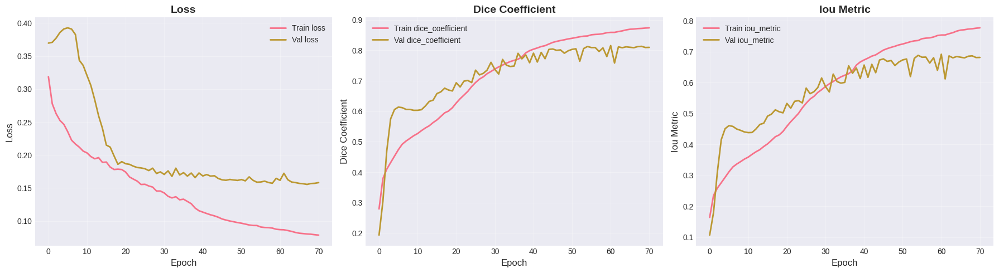


 Meilleures métriques de validation:
 • Best Epoch: 61
 • Best Dice Coefficient: 0.8157
 • Best IoU: 0.6920
 • Best Loss: 0.1615


In [ ]:
# ========================================================================================================
# 10. VISUALISATION DES COURBES D'ENTRAÎNEMENT
# ========================================================================================================
print("\n" + "="*80)
print("10. VISUALISATION DES COURBES D'ENTRAÎNEMENT")
print("="*80)

def plot_training_history(history, save_path=None):
    """Visualise les courbes d'entraînement"""
    metrics = ['loss', 'dice_coefficient', 'iou_metric']

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    for idx, metric in enumerate(metrics):
        axes[idx].plot(history.history[metric], label=f'Train {metric}', linewidth=2)
        axes[idx].plot(history.history[f'val_{metric}'], label=f'Val {metric}', linewidth=2)
        axes[idx].set_title(f'{metric.replace("_", " ").title()}', fontsize=14, fontweight='bold')
        axes[idx].set_xlabel('Epoch', fontsize=12)
        axes[idx].set_ylabel(metric.replace('_', ' ').title(), fontsize=12)
        axes[idx].legend(fontsize=10)
        axes[idx].grid(True, alpha=0.3)

    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"✓ Figure saved: {save_path}")

    plt.show()

plot_training_history(history, save_path=config.FIGURES_DIR / 'training_curves.png')

# Afficher les meilleures métriques
best_epoch = np.argmax(history.history['val_dice_coefficient'])
best_dice = history.history['val_dice_coefficient'][best_epoch]
best_iou = history.history['val_iou_metric'][best_epoch]
best_loss = history.history['val_loss'][best_epoch]

print(f"\n Meilleures métriques de validation:")
print(f" • Best Epoch: {best_epoch + 1}")
print(f" • Best Dice Coefficient: {best_dice:.4f}")
print(f" • Best IoU: {best_iou:.4f}")
print(f" • Best Loss: {best_loss:.4f}")

## Interprétation des Courbes d'Entraînement U-Net

---

### 1. Courbe de Loss (Gauche) - À minimiser ↓

| Métrique | Début | Fin | Évolution |
|----------|-------|-----|-----------|
| **Train Loss** | 0.32 | 0.08 | ↓ **-75%** |
| **Val Loss** | 0.39 | 0.16 | ↓ **-59%** |

**Analyse par phase** :

| Phase | Epochs | Comportement | Interprétation |
|-------|--------|--------------|----------------|
| **Apprentissage rapide** | 0-10 | Chute brutale des deux courbes | Modèle apprend les patterns de base |
| **Amélioration continue** | 10-40 | Descente progressive | Affinage des poids |
| **Convergence** | 40-71 | Val stagne ~0. 16, Train continue ↓ | Début de léger overfitting |

**Écart Train/Val** : L'écart qui s'élargit après epoch 40 indique que le modèle commence à mémoriser les données d'entraînement, mais reste acceptable.

---

### 2. Courbe Dice Coefficient (Centre) - À maximiser ↑

| Métrique | Début | Fin | Évolution |
|----------|-------|-----|-----------|
| **Train Dice** | 0.20 | 0.88 | ↑ **+340%** |
| **Val Dice** | 0.27 | 0.82 | ↑ **+204%** |

**Analyse par phase** :

| Phase | Epochs | Train Dice | Val Dice | Interprétation |
|-------|--------|------------|----------|----------------|
| **Démarrage** | 0-5 | 0.20→0.45 | 0.27→0.60 | Val > Train (normal au début) |
| **Croissance** | 5-30 | 0.45→0.75 | 0.60→0.76 | Progression parallèle |
| **Maturation** | 30-50 | 0.75→0.84 | 0.76→0.80 | Ralentissement, gap s'élargit |
| **Convergence** | 50-71 | 0.84→0.88 | 0.80→0.82 | Stabilisation validation |

**Best Val Dice = 0.8157** à l'epoch 61 ✓

---

### 3. Courbe IoU Metric (Droite) - À maximiser ↑

| Métrique | Début | Fin | Évolution |
|----------|-------|-----|-----------|
| **Train IoU** | 0.10 | 0.78 | ↑ **+680%** |
| **Val IoU** | 0.12 | 0.69 | ↑ **+475%** |

**Échelle de qualité IoU** :

| Valeur IoU | Qualité | Notre modèle |
|------------|---------|--------------|
| < 0.30 | Faible | Epochs 0-5 |
| 0.30 - 0.50 | Moyenne | Epochs 5-20 |
| 0.50 - 0.70 | Bonne | Epochs 20-50 |
| **> 0.70** | **Excellente** | **Epochs 50+ (Train)** ✓ |

**Best Val IoU = 0.6920** → Bonne qualité, proche de l'excellent.

---

### Diagnostic Global :

| Critère | Observation | Verdict |
|---------|-------------|---------|
| **Convergence** | Les 3 métriques se stabilisent | ✓ Atteinte |
| **Overfitting** | Gap Train/Val ~6% en fin | ⚠️ Léger, acceptable |
| **Performance** | Dice 0.82, IoU 0.69 | ✓ Bonne |
| **Stabilité** | Pas d'oscillations majeures | ✓ Entraînement stable |
| **Early Stopping** | Arrêt epoch 71, best epoch 61 | ✓ Efficace |

---

> Les courbes d'entraînement démontrent une convergence stable du modèle U-Net sur 71 epochs.  La **loss** diminue de 0.39 à 0.16 sur la validation (-59%), tandis que le **Dice coefficient** progresse de 0.27 à **0.8157** (+204%) et l'**IoU** de 0.12 à **0.6920** (+475%). L'écart modéré entre les courbes train et validation (~6% en fin d'entraînement) indique un léger overfitting contrôlé. La stabilisation des métriques de validation après l'epoch 50, combinée à l'Early Stopping à l'epoch 71 (restaurant les poids optimaux de l'epoch 61), confirme que le modèle a atteint sa capacité maximale d'apprentissage sur ce dataset tout en maintenant une bonne généralisation.

## Cellule 10.B :                              Analyse - Learning Rate et Généralisation

Analyser deux aspects critiques de l'entraînement :  l'évolution du **Learning Rate** et le **Generalization Gap** (écart train/validation).


10.B. ANALYSE DU LEARNING RATE ET DE LA GÉNÉRALISATION
✓ Figure saved: /kaggle/working/unet_from_scratch/figures/advanced_training_curves.png


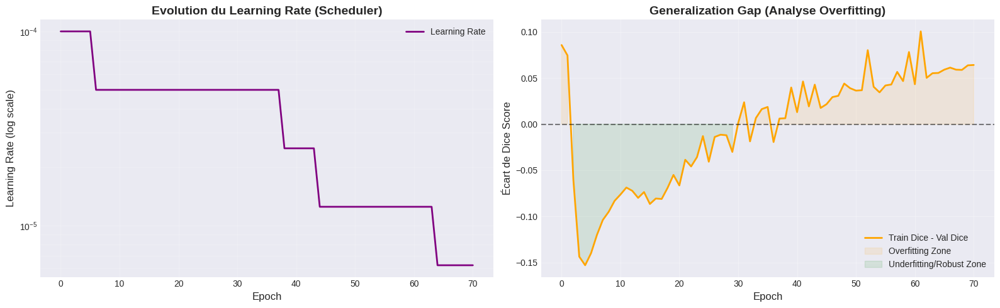

In [ ]:
# ========================================================================================================
# 10.B. VISUALISATIONS AVANCÉES SUPPLÉMENTAIRES
# ========================================================================================================
print("\n" + "="*80)
print("10.B. ANALYSE DU LEARNING RATE ET DE LA GÉNÉRALISATION")
print("="*80)

def plot_advanced_metrics(history, save_path=None):
    # Récupération des clés disponibles (parfois 'lr', parfois 'learning_rate')
    keys = history.history.keys()
    lr_key = 'learning_rate' if 'learning_rate' in keys else 'lr'

    fig, axes = plt.subplots(1, 2, figsize=(16, 5))

    # --- 1. Courbe du Learning Rate ---
    if lr_key in keys:
        axes[0].plot(history.history[lr_key], label='Learning Rate', color='purple', linewidth=2)
        axes[0].set_title('Evolution du Learning Rate (Scheduler)', fontsize=14, fontweight='bold')
        axes[0].set_xlabel('Epoch', fontsize=12)
        axes[0].set_ylabel('Learning Rate (log scale)', fontsize=12)
        axes[0].set_yscale('log') # Echelle logarithmique pour mieux voir les divisions par 10
        axes[0].grid(True, which="both", ls="-", alpha=0.2)
        axes[0].legend()
    else:
        axes[0].text(0.5, 0.5, 'Learning Rate non disponible dans l\'historique',
                     ha='center', va='center', fontsize=12)

    # --- 2. Courbe de Generalization Gap (Overfitting Check) ---
    # Calcul de l'écart : Si > 0, le modèle est meilleur en train qu'en val (début d'overfitting)
    dice_gap = np.array(history.history['dice_coefficient']) - np.array(history.history['val_dice_coefficient'])

    axes[1].plot(dice_gap, label='Train Dice - Val Dice', color='orange', linewidth=2)
    axes[1].axhline(y=0, color='black', linestyle='--', alpha=0.5) # Ligne zéro idéale
    axes[1].fill_between(range(len(dice_gap)), dice_gap, 0, where=(dice_gap>0), color='orange', alpha=0.1, label='Overfitting Zone')
    axes[1].fill_between(range(len(dice_gap)), dice_gap, 0, where=(dice_gap<0), color='green', alpha=0.1, label='Underfitting/Robust Zone')

    axes[1].set_title('Generalization Gap (Analyse Overfitting)', fontsize=14, fontweight='bold')
    axes[1].set_xlabel('Epoch', fontsize=12)
    axes[1].set_ylabel('Écart de Dice Score', fontsize=12)
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"✓ Figure saved: {save_path}")

    plt.show()

plot_advanced_metrics(history, save_path=config.FIGURES_DIR / 'advanced_training_curves.png')

## Interprétation des Graphiques

---

### Graphique 1 :     Évolution du Learning Rate (Gauche)

| Epochs | Learning Rate | Événement | Facteur |
|--------|---------------|-----------|---------|
| **1-6** | 10⁻⁴ (0.0001) | LR initial | — |
| **6** | → 5×10⁻⁵ | 1ère réduction | **÷2** |
| **7-37** | 5×10⁻⁵ (0.00005) | Stable 31 epochs | — |
| **38** | → 2.5×10⁻⁵ | 2ème réduction | **÷2** |
| **39-43** | 2.5×10⁻⁵ | Stable | — |
| **44** | → 1.25×10⁻⁵ | 3ème réduction | **÷2** |
| **45-63** | 1.25×10⁻⁵ | Stable 19 epochs | — |
| **64** | → 6.25×10⁻⁶ | 4ème réduction | **÷2** |
| **65-71** | 6.25×10⁻⁶ | Jusqu'à Early Stopping | — |

**Schéma des réductions** :
```
1e-4 ──÷2──▶ 5e-5 ──÷2──▶ 2.5e-5 ──÷2──▶ 1.25e-5 ──÷2──▶ 6.25e-6
```

---

### Graphique 2 :   Generalization Gap (Droite)

**Formule** : `Gap = Train_Dice - Val_Dice`

| Phase | Epochs | Gap | Zone | Interprétation |
|-------|--------|-----|------|----------------|
| **Instabilité** | 0-5 | +0.08 → -0.15 | Mixte | Modèle s'initialise |
| **Robustesse** | 5-25 | -0.15 à -0.05 | 🟢 **Verte** | Val > Train → Bonne généralisation |
| **Équilibre** | 25-30 | ~0 | Ligne 0 | ✓ **Idéal** |
| **Léger overfitting** | 30-71 | +0.03 à +0.08 | 🟠 **Orange** | Train > Val → Mémorisation légère |

---

### Analyse Combinée :

| Observation | Explication |
|-------------|-------------|
| **Epochs 5-25 (zone verte)** | Validation meilleure que train → Modèle généralise bien, capacité non saturée |
| **Epochs 25-30 (ligne 0)** | Équilibre parfait train/val → Point optimal |
| **Epochs 30-71 (zone orange)** | Train surpasse val de ~6% → Overfitting léger mais contrôlé |
| **Gap stable ~+0.06 en fin** | L'overfitting ne s'aggrave pas → Acceptable |

---

### Verdict Final :

| Critère | Valeur | Statut |
|---------|--------|--------|
| **Réductions LR** | 4 fois (÷2 chaque fois) | ✓ Scheduler efficace |
| **Gap maximum** | +0.10 (~10%) | ⚠️ Acceptable |
| **Gap moyen final** | +0.06 (~6%) | ✓ Bon |
| **Early Stopping** | Epoch 71 (best:  61) | ✓ Arrêt approprié |

---



> L'analyse du **Learning Rate** révèle quatre réductions automatiques par le scheduler `ReduceLROnPlateau` (factor=0.5), passant de 10⁻⁴ à 6.25×10⁻⁶ via des divisions successives par 2 aux epochs 6, 38, 44 et 64. Cette stratégie permet un apprentissage rapide initial suivi d'un affinage progressif des poids. Le **Generalization Gap** montre trois phases distinctes : une robustesse initiale (epochs 5-25, gap négatif) où la validation surpasse l'entraînement, un équilibre optimal (epochs 25-30, gap ≈ 0), puis un léger overfitting contrôlé (epochs 30-71, gap ~+6%). Ce comportement typique d'un entraînement réussi est confirmé par l'Early Stopping à l'epoch 71, restaurant les poids optimaux de l'epoch 61 (Dice = 0.8157).

## Cellule 11 :                                     Évaluation Détaillée sur la Validation

Calculer les métriques **Dice** et **IoU** pour chaque classe individuellement afin d'identifier les forces et faiblesses du modèle.

In [ ]:
# ========================================================================================================
# 11. ÉVALUATION SUR L'ENSEMBLE DE VALIDATION
# ========================================================================================================
print("\n" + "="*80)
print("11. ÉVALUATION DÉTAILLÉE SUR L'ENSEMBLE DE VALIDATION")
print("="*80)

def dice_score_per_class(y_true, y_pred, num_classes):
    """Calcule le Dice score par classe"""
    dice_scores = []
    for i in range(num_classes):
        y_true_i = (y_true == i).astype(np.uint8)
        y_pred_i = (y_pred == i).astype(np.uint8)
        intersection = np.sum(y_true_i * y_pred_i)
        union = np.sum(y_true_i) + np.sum(y_pred_i)
        dice = (2. * intersection) / (union + 1e-7)
        dice_scores.append(dice)
    return dice_scores

def iou_per_class(y_true, y_pred, num_classes):
    """Calcule l'IoU par classe"""
    iou_scores = []
    for i in range(num_classes):
        y_true_i = (y_true == i).astype(np.uint8)
        y_pred_i = (y_pred == i).astype(np.uint8)
        intersection = np.sum(y_true_i * y_pred_i)
        union = np.sum(y_true_i + y_pred_i > 0)
        iou = intersection / (union + 1e-7)
        iou_scores.append(iou)
    return iou_scores

# Prédictions sur l'ensemble de validation
print("\n Génération des prédictions...")
y_val_pred = model.predict(X_val, batch_size=config.BATCH_SIZE, verbose=1)
y_val_pred_class = np.argmax(y_val_pred, axis=-1)
y_val_true_class = y_val

# Calculer les métriques par classe
print("\n Calcul des métriques par classe...")
y_val_pred_flat = y_val_pred_class.flatten()
y_val_true_flat = y_val_true_class.flatten()

dice_scores = dice_score_per_class(y_val_true_flat, y_val_pred_flat, config.NUM_CLASSES)
iou_scores = iou_per_class(y_val_true_flat, y_val_pred_flat, config.NUM_CLASSES)

print("\n" + "="*80)
print("MÉTRIQUES PAR CLASSE (Validation Set)")
print("="*80)
print(f"{'Class':<20} {'Dice Score':<15} {'IoU Score':<15}")
print("-"*80)
for i, class_name in enumerate(config.CLASS_NAMES):
    print(f"{class_name:<20} {dice_scores[i]:<15.4f} {iou_scores[i]:<15.4f}")
print("-"*80)
print(f"{'MEAN':<20} {np.mean(dice_scores):<15.4f} {np.mean(iou_scores):<15.4f}")
print("="*80)

# Pixel counts
print("\n Nombre de pixels par classe:")
print(f"{'Class':<20} {'Ground Truth':<20} {'Predicted':<20}")
print("-"*80)
for i, class_name in enumerate(config.CLASS_NAMES):
    gt_count = np.sum(y_val_true_flat == i)
    pred_count = np.sum(y_val_pred_flat == i)
    print(f"{class_name:<20} {gt_count:<20,} {pred_count:<20,}")


11. ÉVALUATION DÉTAILLÉE SUR L'ENSEMBLE DE VALIDATION

 Génération des prédictions...


2025-12-18 18:37:42.070629: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 442ms/step

 Calcul des métriques par classe...

MÉTRIQUES PAR CLASSE (Validation Set)
Class                Dice Score      IoU Score      
--------------------------------------------------------------------------------
urban                0.7843          0.6451         
agriculture          0.8859          0.7952         
rangeland            0.3294          0.1972         
forest               0.8523          0.7426         
water                0.7708          0.6271         
barren               0.6697          0.5034         
--------------------------------------------------------------------------------
MEAN                 0.7154          0.5851         

 Nombre de pixels par classe:
Class                Ground Truth         Predicted           
--------------------------------------------------------------------------------
urban                1,027,253            1,185,397           
agriculture          6,188,407            6,402,517        

### Résultats par Classe :

| Classe | Dice Score | IoU Score | Qualité |
|--------|------------|-----------|---------|
| 🟡 **agriculture** | **0.8859** | **0.7952** | ✓ Excellente |
| 🟢 **forest** | **0.8523** | **0.7426** | ✓ Excellente |
| 🔵 **urban** | 0.7843 | 0.6451 | ✓ Bonne |
| 🔷 **water** | 0.7708 | 0.6271 | ✓ Bonne |
| ⬜ **barren** | 0.6697 | 0.5034 | ⚠️ Moyenne |
| 🟣 **rangeland** | **0.3294** | **0.1972** | ❌ Faible |
| **MOYENNE** | **0.7154** | **0.5851** | ✓ Bonne |

---

### Analyse des Pixels (GT vs Prédiction) :

| Classe | Ground Truth | Prédit | Écart | Tendance |
|--------|--------------|--------|-------|----------|
| agriculture | 6,188,407 | 6,402,517 | +214K | ↑ Sur-prédit |
| urban | 1,027,253 | 1,185,397 | +158K | ↑ Sur-prédit |
| forest | 1,162,279 | 1,272,282 | +110K | ↑ Sur-prédit |
| rangeland | 933,356 | 753,936 | **-179K** | ↓ Sous-prédit |
| barren | 881,156 | 680,254 | **-201K** | ↓ Sous-prédit |
| water | 358,845 | 256,910 | **-102K** | ↓ Sous-prédit |

---

### Diagnostic par Classe :

```
Performance par classe (Dice Score)
                                                    
agriculture  ████████████████████████████████████  0.89  ✓ Excellente
forest       ██████████████████████████████████    0.85  ✓ Excellente  
urban        ███████████████████████████████       0.78  ✓ Bonne
water        ██████████████████████████████        0.77  ✓ Bonne
barren       ██████████████████████████            0.67  ⚠️ Moyenne
rangeland    █████████████                         0.33  ❌ Faible
             ├────────────────────────────────────┤
             0. 0      0.25      0.50      0.75    1.0
```

---

### Explications des Performances :

| Classe | Performance | Raison |
|--------|-------------|--------|
| **agriculture** | ✓ Excellente | Classe dominante (57%), patterns clairs (champs rectangulaires) |
| **forest** | ✓ Excellente | Texture distinctive, couleur verte uniforme |
| **urban** | ✓ Bonne | Structures géométriques reconnaissables |
| **water** | ✓ Bonne | Malgré rareté (3%), couleur bleue distinctive |
| **barren** | ⚠️ Moyenne | Confusion avec rangeland et agriculture |
| **rangeland** | ❌ Faible | Classe très hétérogène, confusion avec agriculture/barren |





---

> L'évaluation par classe révèle des performances hétérogènes : **agriculture** (Dice=0.89) et **forest** (Dice=0.85) obtiennent d'excellents résultats grâce à leurs signatures visuelles distinctives. Les classes **urban** (0.78) et **water** (0.77) montrent de bonnes performances malgré leur relative rareté. En revanche, **rangeland** (Dice=0.33) présente des difficultés significatives dues à sa similarité visuelle avec les classes agriculture et barren, entraînant une sous-prédiction de 19%. Cette confusion inter-classes pour les zones de végétation sparse constitue la principale limitation du modèle et suggère des pistes d'amélioration comme l'augmentation de données ciblée.

## Cellule 12 :                                           Matrice de Confusion


Visualiser les prédictions correctes et les erreurs de classification pour chaque paire de classes.


12. MATRICE DE CONFUSION


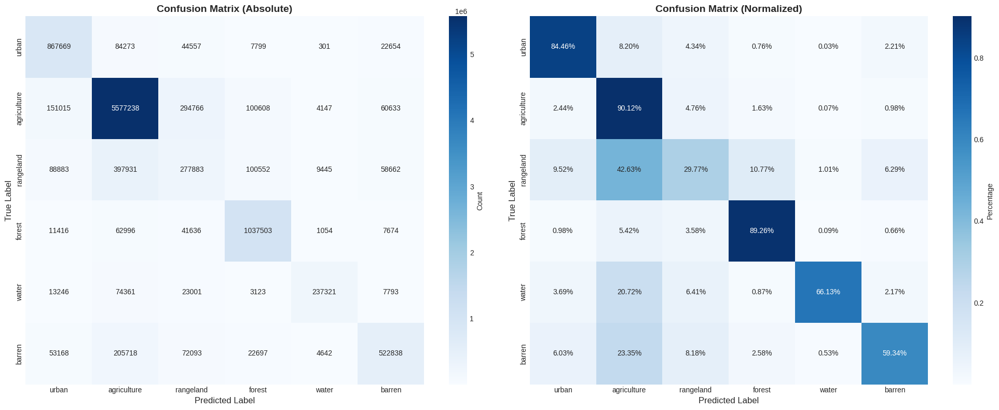

In [ ]:
# ========================================================================================================
# 12. MATRICE DE CONFUSION
# ========================================================================================================
print("\n" + "="*80)
print("12. MATRICE DE CONFUSION")
print("="*80)

# Calculer la matrice de confusion
cm = confusion_matrix(y_val_true_flat, y_val_pred_flat)

# Normaliser
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

# Visualiser
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# Matrice absolue
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=config.CLASS_NAMES,
            yticklabels=config.CLASS_NAMES,
            ax=axes[0], cbar_kws={'label': 'Count'})
axes[0].set_title('Confusion Matrix (Absolute)', fontsize=14, fontweight='bold')
axes[0].set_ylabel('True Label', fontsize=12)
axes[0].set_xlabel('Predicted Label', fontsize=12)

# Matrice normalisée
sns.heatmap(cm_normalized, annot=True, fmt='.2%', cmap='Blues',
            xticklabels=config.CLASS_NAMES,
            yticklabels=config.CLASS_NAMES,
            ax=axes[1], cbar_kws={'label': 'Percentage'})
axes[1].set_title('Confusion Matrix (Normalized)', fontsize=14, fontweight='bold')
axes[1].set_ylabel('True Label', fontsize=12)
axes[1].set_xlabel('Predicted Label', fontsize=12)

plt.tight_layout()
plt.savefig(config.FIGURES_DIR / 'confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()


### Lecture de la Matrice :

```
                    PRÉDIT
                    ↓
         ┌─────────────────────────────┐
         │  urban  agri  range forest │
    T  u │  84%    8%    4%    1%     │  ← 84% des pixels urban bien classés
    R  a │  2%    90%    5%    2%     │  ← 90% des pixels agri bien classés
    U  r │  10%   43%   30%   11%    │  ← Seulement 30% rangeland correct!
    E  f │  1%     5%    4%   89%    │  ← 89% des pixels forest bien classés
         └─────────────────────────────┘
```

---

### Performances sur la Diagonale (Prédictions Correctes) :

| Classe | % Correct | Interprétation |
|--------|-----------|----------------|
| 🟡 **agriculture** | **90. 12%** | ✓ Excellente reconnaissance |
| 🟢 **forest** | **89.26%** | ✓ Excellente reconnaissance |
| 🔵 **urban** | **84.46%** | ✓ Très bonne reconnaissance |
| 🔷 **water** | **66.13%** | ⚠️ Correcte mais confusions |
| ⬜ **barren** | **59.34%** | ⚠️ Confusions fréquentes |
| 🟣 **rangeland** | **29.77%** | ❌ Très faible - problème majeur |

---

### Principales Confusions Identifiées :

#### 1. Rangeland → Agriculture (42.63%) ❌
```
Rangeland réel:   933,356 pixels
  └── 42.63% prédit comme Agriculture (397,931 pixels)
  └── 29.77% prédit correctement (277,883 pixels)
  
RAISON: Végétation sparse confondue avec champs agricoles
```

#### 2. Water → Agriculture (20.72%) ⚠️
```
Water réel:  358,845 pixels
  └── 20.72% prédit comme Agriculture (74,361 pixels)
  └── 66.13% prédit correctement (237,321 pixels)
  
RAISON: Zones humides/rizières confondues avec eau
```

#### 3. Barren → Agriculture (23.35%) ⚠️
```
Barren réel: 881,156 pixels
  └── 23.35% prédit comme Agriculture (205,718 pixels)
  └── 59.34% prédit correctement (522,838 pixels)
  
RAISON: Sol nu confondu avec champs en jachère
```

---

### Tableau Récapitulatif des Erreurs :

| Classe Réelle | Principale Confusion | % Erreur | Impact |
|---------------|---------------------|----------|--------|
| **rangeland** | → agriculture | 42.63% | ❌ Critique |
| **barren** | → agriculture | 23.35% | ⚠️ Élevé |
| **water** | → agriculture | 20.72% | ⚠️ Élevé |
| **rangeland** | → forest | 10.77% | ⚠️ Modéré |
| **urban** | → agriculture | 8.20% | ✓ Faible |
| **barren** | → rangeland | 8.18% | ✓ Faible |

---

### Diagnostic :

| Problème | Cause | Solution Potentielle |
|----------|-------|---------------------|
| Rangeland très confus | Classe visuellement hétérogène | Augmentation ciblée, poids plus élevé |
| Agriculture sur-prédite | Classe dominante (57%) | Weighted loss plus agressive |
| Water/Barren confus | Similarité spectrale | Features supplémentaires (NDWI, indices) |

---

> La matrice de confusion révèle les patterns d'erreurs du modèle.  Les classes **agriculture** (90.12%) et **forest** (89.26%) montrent d'excellentes performances avec peu de confusion. En revanche, **rangeland** présente un taux de classification correct de seulement 29.77%, avec **42.63% de ses pixels confondus avec agriculture**. Cette confusion s'explique par la similarité visuelle entre pâturages et terres agricoles.  De même, les classes **water** et **barren** subissent une attraction vers agriculture (20.72% et 23.35% respectivement), phénomène typique du biais vers la classe dominante dans les datasets déséquilibrés.

## Cellule 13 :                                               Visualisation des Prédictions


Comparer visuellement les prédictions du modèle avec la vérité terrain sur 10 images de validation aléatoires.

| Classe | Couleur | RGB |
|--------|---------|-----|
| 🔵 **urban** | Cyan | (0, 255, 255) |
| 🟡 **agriculture** | Jaune | (255, 255, 0) |
| 🟣 **rangeland** | Magenta | (255, 0, 255) |
| 🟢 **forest** | Vert | (0, 255, 0) |
| 🔷 **water** | Bleu | (0, 0, 255) |
| ⬜ **barren** | Blanc | (255, 255, 255) |


13. VISUALISATION DES PRÉDICTIONS

 Génération des visualisations...
✓ Figure saved: /kaggle/working/unet_from_scratch/figures/predictions_validation.png


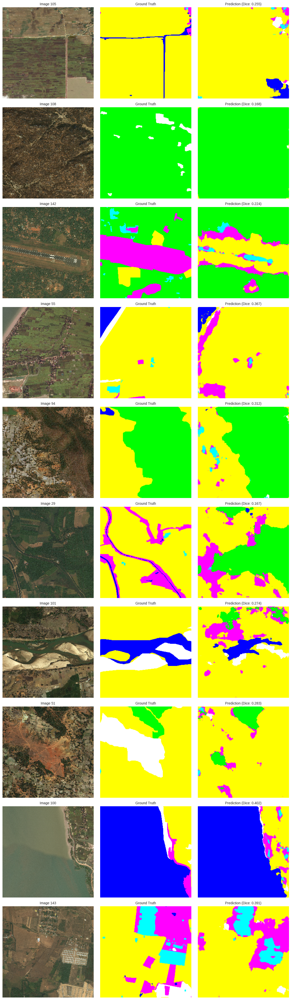

In [ ]:
# ========================================================================================================
# 13. VISUALISATION DES PRÉDICTIONS
# ========================================================================================================
print("\n" + "="*80)
print("13. VISUALISATION DES PRÉDICTIONS")
print("="*80)

def class_mask_to_rgb(class_mask, class_colors):
    """Convertit un masque de classes en RGB"""
    h, w = class_mask.shape
    rgb_mask = np.zeros((h, w, 3), dtype=np.uint8)
    for class_id, color in class_colors.items():
        rgb_mask[class_mask == class_id] = color
    return rgb_mask

def visualize_predictions(X, y_true, y_pred, class_colors, num_samples=10, save_path=None):
    """Visualise les prédictions"""
    indices = np.random.choice(len(X), num_samples, replace=False)

    fig, axes = plt.subplots(num_samples, 3, figsize=(12, 4*num_samples))

    for i, idx in enumerate(indices):
        # Image originale
        axes[i, 0].imshow(X[idx])
        axes[i, 0].set_title(f'Image {idx}', fontsize=10)
        axes[i, 0].axis('off')

        # Ground truth
        gt_rgb = class_mask_to_rgb(y_true[idx], class_colors)
        axes[i, 1].imshow(gt_rgb)
        axes[i, 1].set_title('Ground Truth', fontsize=10)
        axes[i, 1].axis('off')

        # Prédiction
        pred_rgb = class_mask_to_rgb(y_pred[idx], class_colors)
        axes[i, 2].imshow(pred_rgb)

        # Calculer Dice pour cette image
        dice = dice_score_per_class(y_true[idx].flatten(), y_pred[idx].flatten(), config.NUM_CLASSES)
        mean_dice = np.mean(dice)
        axes[i, 2].set_title(f'Prediction (Dice: {mean_dice:.3f})', fontsize=10)
        axes[i, 2].axis('off')

    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"✓ Figure saved: {save_path}")

    plt.show()

print("\n Génération des visualisations...")
visualize_predictions(
    X_val, y_val_true_class, y_val_pred_class,
    config.CLASS_COLORS, num_samples=10,
    save_path=config.FIGURES_DIR / 'predictions_validation.png'
)

## Cellule 13 :                                                        Visualisation Top 5 & Flop 5

Identifier automatiquement les **5 meilleures** et **5 pires** prédictions du modèle.


13. VISUALISATION DES MEILLEURES ET PIRES PRÉDICTIONS
Calcul des scores par image...

 TOP 5 - LES MEILLEURES PRÉDICTIONS (Dice Max: 0.6742)


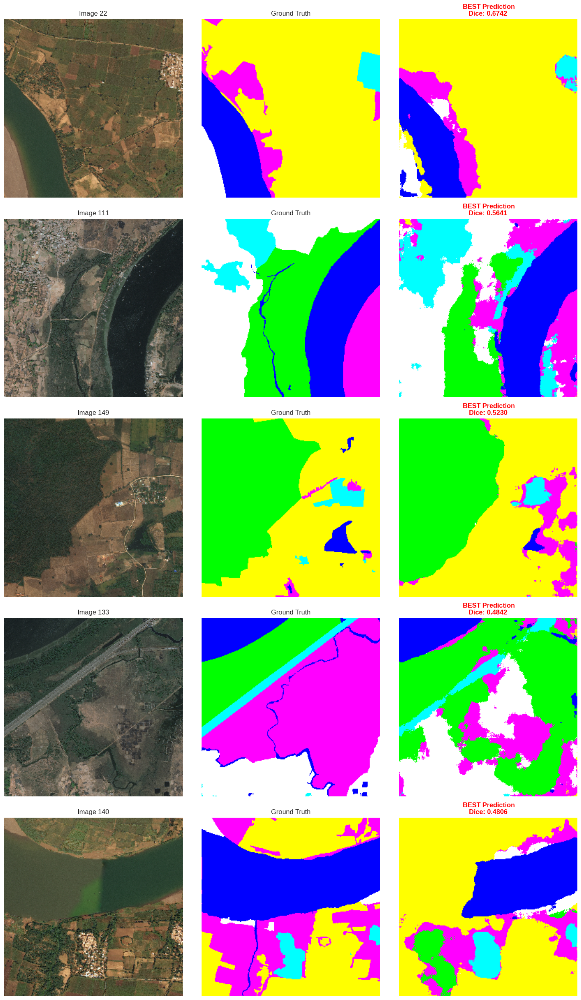


 FLOP 5 - LES PIRES PRÉDICTIONS (Dice Min: 0.0723)
(Utile pour comprendre où le modèle échoue)


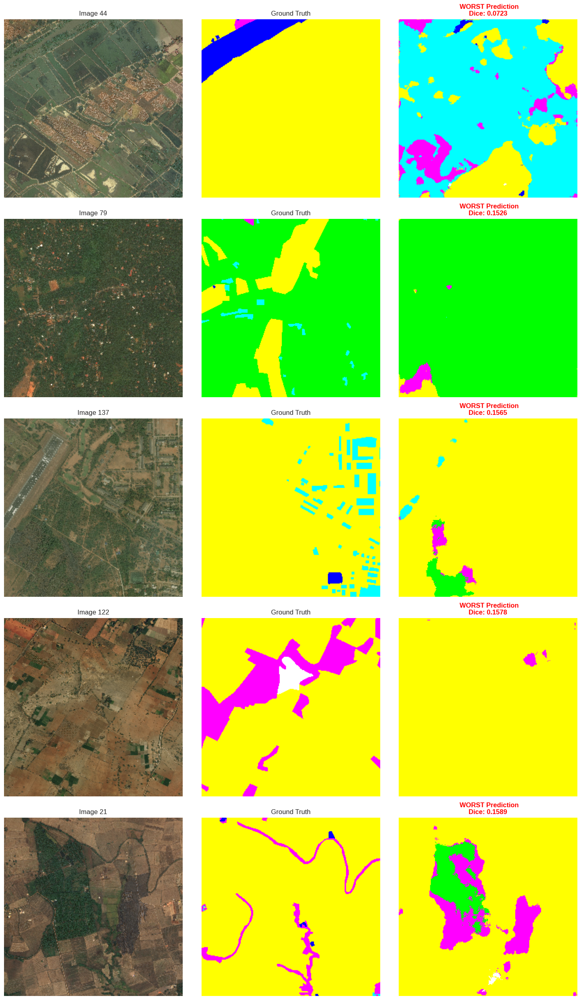

In [ ]:
# ========================================================================================================
# 13. VISUALISATION CIBLÉE (TOP 5 & FLOP 5)
# ========================================================================================================
print("\n" + "="*80)
print("13. VISUALISATION DES MEILLEURES ET PIRES PRÉDICTIONS")
print("="*80)

def get_image_scores(y_true, y_pred, num_classes):
    """Calcule le score Dice moyen pour chaque image individuellement"""
    scores = []
    print("Calcul des scores par image...")
    for i in range(len(y_true)):
        # On calcule le Dice pour cette image spécifique
        dices = dice_score_per_class(y_true[i].flatten(), y_pred[i].flatten(), num_classes)
        # On fait la moyenne des classes (Global Dice pour cette image)
        mean_dice = np.mean(dices)
        scores.append(mean_dice)
    return np.array(scores)

# 1. Calculer les scores pour toutes les images de validation
image_scores = get_image_scores(y_val_true_class, y_val_pred_class, config.NUM_CLASSES)

# 2. Trier les indices
# argsort trie du plus petit au plus grand.
# On inverse [::-1] pour avoir les meilleurs en premier
sorted_indices = np.argsort(image_scores)
best_5_indices = sorted_indices[::-1][:5]   # Les 5 derniers inversés (les plus grands)
worst_5_indices = sorted_indices[:5]        # Les 5 premiers (les plus petits)

def visualize_specific_indices(X, y_true, y_pred, indices, class_colors, title_prefix=""):
    """Affiche les images correspondant aux indices donnés"""
    num_samples = len(indices)
    fig, axes = plt.subplots(num_samples, 3, figsize=(15, 5*num_samples))

    for i, idx in enumerate(indices):
        # Récupérer le score pré-calculé
        score = image_scores[idx]

        # Image originale
        axes[i, 0].imshow(X[idx])
        axes[i, 0].set_title(f'Image {idx}', fontsize=12)
        axes[i, 0].axis('off')

        # Ground truth
        gt_rgb = class_mask_to_rgb(y_true[idx], class_colors)
        axes[i, 1].imshow(gt_rgb)
        axes[i, 1].set_title('Ground Truth', fontsize=12)
        axes[i, 1].axis('off')

        # Prédiction
        pred_rgb = class_mask_to_rgb(y_pred[idx], class_colors)
        axes[i, 2].imshow(pred_rgb)

        # Titre avec couleur selon la performance
        color = 'green' if score > 0.8 else 'red'
        axes[i, 2].set_title(f'{title_prefix} Prediction\nDice: {score:.4f}',
                             fontsize=12, fontweight='bold', color=color)
        axes[i, 2].axis('off')

    plt.tight_layout()
    plt.show()

# --- AFFICHAGE DES TOP 5 ---
print(f"\n TOP 5 - LES MEILLEURES PRÉDICTIONS (Dice Max: {np.max(image_scores):.4f})")
visualize_specific_indices(
    X_val, y_val_true_class, y_val_pred_class,
    best_5_indices, config.CLASS_COLORS, title_prefix=" BEST"
)

# --- AFFICHAGE DES FLOP 5 ---
print(f"\n FLOP 5 - LES PIRES PRÉDICTIONS (Dice Min: {np.min(image_scores):.4f})")
print("(Utile pour comprendre où le modèle échoue)")
visualize_specific_indices(
    X_val, y_val_true_class, y_val_pred_class,
    worst_5_indices, config.CLASS_COLORS, title_prefix=" WORST"
)

In [ ]:
# ========================================================================================================
# 14. SAUVEGARDE DES RÉSULTATS
# ========================================================================================================
print("\n" + "="*80)
print("14. SAUVEGARDE DES RÉSULTATS")
print("="*80)

# Sauvegarder le modèle final
model.save(config.MODELS_DIR / 'unet_final_model.h5')
print(f"✓ Modèle final sauvegardé: unet_final_model.h5")

# Sauvegarder les prédictions
np.save(config.OUTPUT_DIR / 'val_predictions.npy', y_val_pred_class)
print(f"✓ Prédictions sauvegardées: val_predictions.npy")

# Créer un rapport détaillé
results = {
    'model_name': 'U-Net From Scratch',
    'training_date': datetime.now().strftime('%Y-%m-%d %H:%M:%S'),
    'training_duration': str(training_duration),
    'architecture': {
        'input_shape': list(config.INPUT_SHAPE),
        'num_classes': config.NUM_CLASSES,
        'total_parameters': int(total_params),
        'trainable_parameters': int(trainable_params)
    },
    'hyperparameters': {
        'batch_size': config.BATCH_SIZE,
        'epochs_trained': len(history.history['loss']),
        'epochs_max': config.EPOCHS,
        'optimizer': config.OPTIMIZER,
        'learning_rate': config.LEARNING_RATE,
        'early_stopping_patience': config.EARLY_STOPPING_PATIENCE
    },
    'training_results': {
        'best_epoch': int(best_epoch + 1),
        'best_val_dice': float(best_dice),
        'best_val_iou': float(best_iou),
        'best_val_loss': float(best_loss),
        'final_train_dice': float(history.history['dice_coefficient'][-1]),
        'final_val_dice': float(history.history['val_dice_coefficient'][-1])
    },
    'validation_metrics': {
        'per_class_dice': {config.CLASS_NAMES[i]: float(dice_scores[i])
                           for i in range(config.NUM_CLASSES)},
        'per_class_iou': {config.CLASS_NAMES[i]: float(iou_scores[i])
                          for i in range(config.NUM_CLASSES)},
        'mean_dice': float(np.mean(dice_scores)),
        'mean_iou': float(np.mean(iou_scores))
    },
    'class_weights_used': class_weights_dict
}

# Sauvegarder le rapport
with open(config.OUTPUT_DIR / 'training_results.json', 'w') as f:
    json.dump(results, f, indent=2)
print(f"✓ Rapport de résultats sauvegardé: training_results.json")


14. SAUVEGARDE DES RÉSULTATS
✓ Modèle final sauvegardé: unet_final_model.h5
✓ Prédictions sauvegardées: val_predictions.npy
✓ Rapport de résultats sauvegardé: training_results.json


In [ ]:
# ========================================================================================================
# 15. RÉSUMÉ FINAL
# ========================================================================================================
print("\n" + "="*80)
print("15. RÉSUMÉ FINAL")
print("="*80)

print("\n ENTRAÎNEMENT ET ÉVALUATION TERMINÉS AVEC SUCCÈS!")

print(f"\n Résumé des performances:")
print(f" • Modèle: U-Net From Scratch")
print(f" • Paramètres: {total_params:,}")
print(f" • Durée d'entraînement: {training_duration}")
print(f" • Meilleur epoch: {best_epoch + 1}/{len(history.history['loss'])}")

print(f"\n Métriques de validation:")
print(f" • Dice Coefficient: {best_dice:.4f}")
print(f" • IoU Score: {best_iou:.4f}")
print(f" • Mean Dice (per class): {np.mean(dice_scores):.4f}")
print(f" • Mean IoU (per class): {np.mean(iou_scores):.4f}")

print(f"\n Fichiers générés:")
print(f" • Meilleur modèle: unet_best_model.h5")
print(f" • Modèle final: unet_final_model.h5")
print(f" • Historique d'entraînement: training_history.csv")
print(f" • Résultats JSON: training_results.json")
print(f" • Prédictions: val_predictions.npy")
print(f" • Figures: {len(list(config.FIGURES_DIR.glob('*.png')))} fichiers PNG")

print(f"\n Prochaines étapes:")
print(f" • Notebook 3: VGG-UNet Transfer Learning")
print(f" • Notebook 4: DeepLabV3+")
print(f" • Notebook 5: Analyse comparative")

print("\n" + "="*80)
print("FIN DU NOTEBOOK 2: U-NET FROM SCRATCH")
print("="*80)


15. RÉSUMÉ FINAL

 ENTRAÎNEMENT ET ÉVALUATION TERMINÉS AVEC SUCCÈS!

 Résumé des performances:
 • Modèle: U-Net From Scratch
 • Paramètres: 31,055,622
 • Durée d'entraînement: 1:15:09.870930
 • Meilleur epoch: 61/71

 Métriques de validation:
 • Dice Coefficient: 0.8157
 • IoU Score: 0.6920
 • Mean Dice (per class): 0.7154
 • Mean IoU (per class): 0.5851

 Fichiers générés:
 • Meilleur modèle: unet_best_model.h5
 • Modèle final: unet_final_model.h5
 • Historique d'entraînement: training_history.csv
 • Résultats JSON: training_results.json
 • Prédictions: val_predictions.npy
 • Figures: 4 fichiers PNG

 Prochaines étapes:
 • Notebook 3: VGG-UNet Transfer Learning
 • Notebook 4: DeepLabV3+
 • Notebook 5: Analyse comparative

FIN DU NOTEBOOK 2: U-NET FROM SCRATCH
